<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Backtesting/WF_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
AIM: Understand walkforward framework for backtesting

Backtest a strategy(MA crossover : Long when when price closes above the moving average and short when it falls below)
Test settings
Performance metrics
'''

/tmp/ipykernel_8255/2039684030.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('^GSPC', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2020-01-02  3257.850098  3258.139893  3235.530029  3244.669922  3459930000
2020-01-03  3234.850098  3246.149902  3222.340088  3226.360107  3484700000
2020-01-06  3246.280029  3246.840088  3214.639893  3217.550049  3702460000
2020-01-07  3237.179932  3244.909912  3232.429932  3241.860107  3435910000
2020-01-08  3253.050049  3267.070068  3236.669922  3238.590088  3726840000


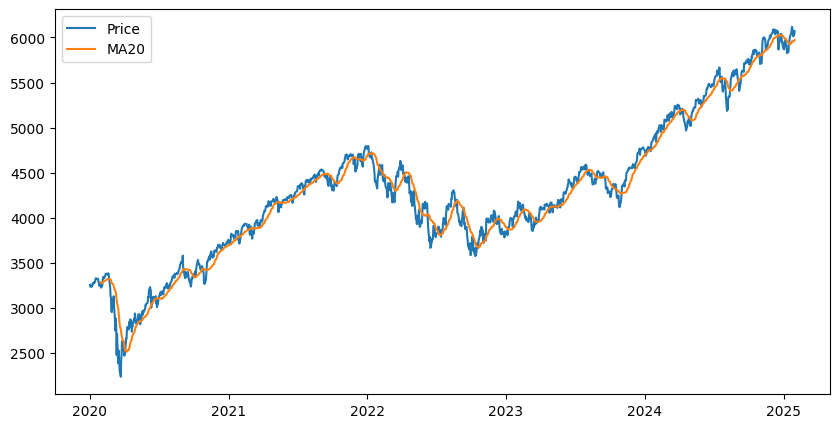

Ticker            ^GSPC         MA20  buy/sell
Date                                          
2020-01-02  3257.850098          NaN         0
2020-01-03  3234.850098          NaN         0
2020-01-06  3246.280029          NaN         0
2020-01-07  3237.179932          NaN         0
2020-01-08  3253.050049          NaN         0
2020-01-09  3274.699951          NaN         0
2020-01-10  3265.350098          NaN         0
2020-01-13  3288.129883          NaN         0
2020-01-14  3283.149902          NaN         0
2020-01-15  3289.290039          NaN         0
2020-01-16  3316.810059          NaN         0
2020-01-17  3329.620117          NaN         0
2020-01-21  3320.790039          NaN         0
2020-01-22  3321.750000          NaN         0
2020-01-23  3325.540039          NaN         0
2020-01-24  3295.469971          NaN         0
2020-01-27  3243.629883          NaN         0
2020-01-28  3276.239990          NaN         0
2020-01-29  3273.399902          NaN         0
2020-01-30  3

In [8]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

start_date = '2020-01-01'
end_date = '2025-01-31'

data = yf.download('^GSPC', start=start_date, end=end_date)
print(data.head())

#rolling average of the last 20 days
price = data['Close'].copy()

price['MA20'] = price['^GSPC'].rolling(20).mean()

#plotting MA with prices
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.legend()
plt.show()

#initial portfolio
port_i = 100

#trading, trades at crossover
price['buy/sell'] = np.where(price['^GSPC'] > price['MA20'], 1, 0)
#price['sell'] = np.where(price['^GSPC'] < price['MA20'], 1, 0)

print(price.head(21))

Ticker            ^GSPC         MA20  buy/sell       ret  ret_strat  \
Date                                                                  
2020-02-12  3379.449951  3307.284998         1  0.006442  -0.006442   
2020-02-13  3373.939941  3311.517493         1 -0.001632  -0.001632   
2020-02-14  3380.159912  3314.684985         1  0.001842   0.001842   
2020-02-18  3370.290039  3316.718481         1 -0.002924  -0.002924   
2020-02-19  3386.149902  3319.986475         1  0.004695   0.004695   
2020-02-20  3373.229980  3322.560474         1 -0.003823  -0.003823   
2020-02-21  3337.750000  3323.170972         1 -0.010574  -0.010574   
2020-02-24  3225.889893  3319.691968         0 -0.034088  -0.034088   
2020-02-25  3128.209961  3313.920972         0 -0.030748   0.030748   
2020-02-26  3116.389893  3305.928467         0 -0.003786   0.003786   
2020-02-27  2978.760010  3291.196472         0 -0.045168   0.045168   
2020-02-28  2954.219971  3274.724475         0 -0.008272   0.008272   
2020-0

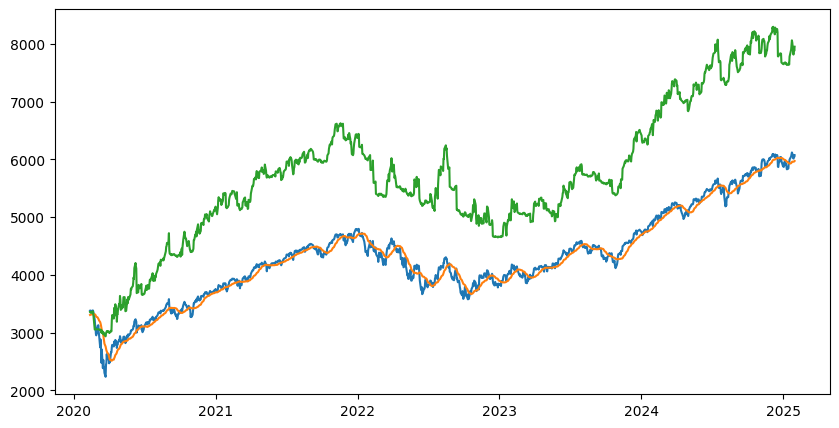

In [18]:
price['ret'] = np.log(price['^GSPC'] / price['^GSPC'].shift(1))
price.dropna(inplace=True)
price

# Strategy returns are
# ret_strat(t) = [buy/sell signal(t-1)] * [ret(t)]

price['ret_strat'] = np.where(price['buy/sell'].shift(1) == 1, price['ret'], -price['ret'])
price['cum_ret_strat'] = price['^GSPC'] * (1 + price['ret_strat'].cumsum())
print(price.head(41))

#plot
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.plot(price['cum_ret_strat'], label='strategy')

In [17]:
price['return_daily'] = np.log(price['^GSPC'].shift(-1)/price['^GSPC'])
price['return'] = np.where(price['buy'] == 1, price['return_daily'], 0)
price['return'] = np.where(price['sell'] == 1, -price['return_daily'], price['return'])
price.dropna(inplace=True)
price['pf_value'] = price['^GSPC']*(1+price['return'].cumsum())
price.head(21)

Ticker,^GSPC,MA20,buy,sell,return_daily,return,pf_value
Date,,,,,,,
2020-01-31,3225.520020,3279.220496,0,1,0.007228,-0.007228,3202.204588
2020-02-03,3248.919922,3279.923987,0,1,0.014869,-0.014869,3177.126129
2020-02-04,3297.590088,3282.489490,1,0,0.011188,0.011188,3261.613502
2020-02-05,3334.689941,3287.364990,1,0,0.003320,0.003320,3309.380285
2020-02-06,3345.780029,3292.001489,1,0,-0.005415,-0.005415,3302.267160
2020-02-07,3327.709961,3294.651990,1,0,0.007300,0.007300,3308.723350
2020-02-10,3352.090088,3298.988989,1,0,0.001687,0.001687,3338.619512
2020-02-11,3357.750000,3302.469995,1,0,0.006442,0.006442,3365.886812
2020-02-12,3379.449951,3307.284998,1,0,-0.001632,-0.001632,3382.124842


In [14]:
#performance metrics to compare afterwards
days_in_trade = 0
buy_rets = []
sell_rets = []
trade_flag = 1
sum_buy = 0
sum_sell = 0

portfolio_i = price['^GSPC'][0]

for i in range(len(price)):
  if (price['sell'][i] == price['sell'][i-1]):
    sum_sell += price['return'][i]
    days_in_trade += 1
    trade_flag = 0

  if (price['sell'][i] != price['buy'][i-1]):
    trade_flag = 1
    sum_sell += price['return'][i]
    days_in_trade += 1




/tmp/ipykernel_3276/568810329.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portfolio_i = price['^GSPC'][0]


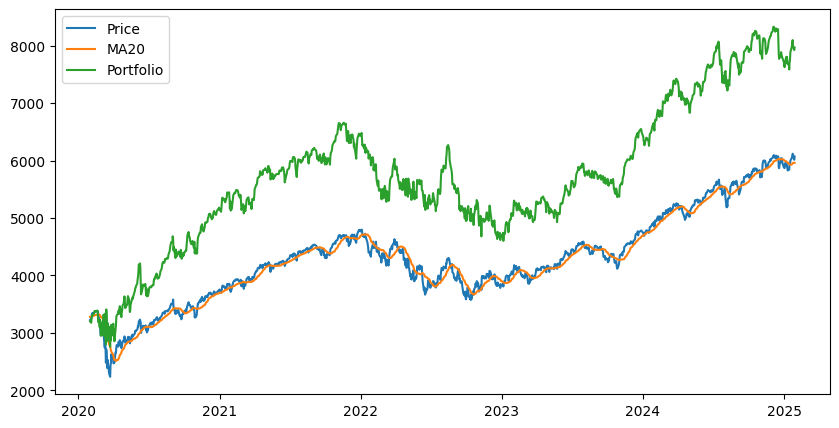

In [10]:
'''
portfolio_i = 3283

buy_ret = np.cumsum(np.where(price['buy'] == 1, price['return'], 0))
buy_ret
sell_ret = -np.cumsum(np.where(price['sell'] == 1, price['return'], 0))
sell_ret

portfolio_ret = (1 + buy_ret + sell_ret) * portfolio_i
portfolio_ret
'''
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.plot(price['pf_value'], label='Portfolio')
plt.legend()
plt.show()